In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Titanic-Dataset.csv")

print(df.head())
print(df.shape)
print(df.info())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
(8

In [9]:
# Check missing values
print(df.isnull().sum())

# Remove duplicate rows
df.drop_duplicates(inplace=True)

# Fill missing Age with median
df['Age'].fillna(df['Age'].median(), inplace=True)

print(df)

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age              0
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64
     PassengerId  Survived  Pclass  \
0              1         0       3   
1              2         1       1   
2              3         1       3   
3              4         1       1   
4              5         0       3   
..           ...       ...     ...   
886          887         0       2   
887          888         1       1   
888          889         0       3   
889          890         1       1   
890          891         0       3   

                                                  Name     Sex   Age  SibSp  \
0                              Braund, Mr. Owen Harris    male  22.0      1   
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                               Heikkinen, Miss. Laina  female  2

/var/folders/4m/tbqbhwhx7nb3776bqrmwh34r0000gn/T/ipykernel_11783/1988048993.py:8: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Age'].fillna(df['Age'].median(), inplace=True)


In [11]:
female = df[(df['Age'] > 40) & (df['Sex'] == 'female')]

print(female)
print("Total passengers:", len(female))

     PassengerId  Survived  Pclass  \
11            12         1       1   
15            16         1       2   
52            53         1       1   
132          133         0       3   
167          168         0       3   
177          178         0       1   
194          195         1       1   
195          196         1       1   
254          255         0       3   
259          260         1       2   
268          269         1       1   
272          273         1       2   
275          276         1       1   
276          277         0       3   
299          300         1       1   
337          338         1       1   
362          363         0       3   
366          367         1       1   
380          381         1       1   
432          433         1       2   
440          441         1       2   
458          459         1       2   
483          484         1       3   
496          497         1       1   
513          514         1       1   
523         

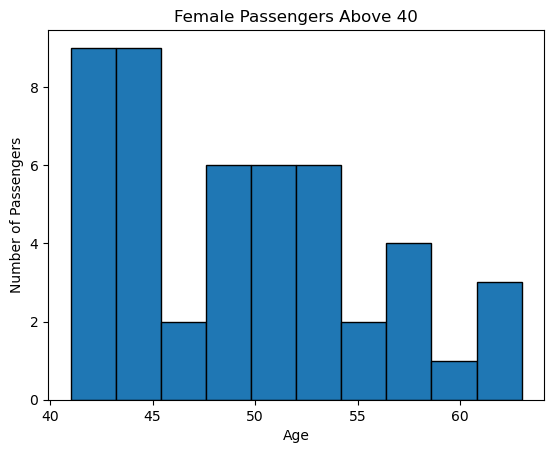

In [12]:
plt.hist(female['Age'], bins=10, edgecolor='black')

plt.title("Female Passengers Above 40")
plt.xlabel("Age")
plt.ylabel("Number of Passengers")

plt.show()

In [13]:
class1 = df[df['Pclass'] == 1]

print(class1)

# Statistical description
print(class1.describe())

# Complete description
print(class1.describe(include='all'))

     PassengerId  Survived  Pclass  \
1              2         1       1   
3              4         1       1   
6              7         0       1   
11            12         1       1   
23            24         1       1   
..           ...       ...     ...   
871          872         1       1   
872          873         0       1   
879          880         1       1   
887          888         1       1   
889          890         1       1   

                                                  Name     Sex   Age  SibSp  \
1    Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
3         Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
6                              McCarthy, Mr. Timothy J    male  54.0      0   
11                            Bonnell, Miss. Elizabeth  female  58.0      0   
23                        Sloper, Mr. William Thompson    male  28.0      0   
..                                                 ...     ...   ... 

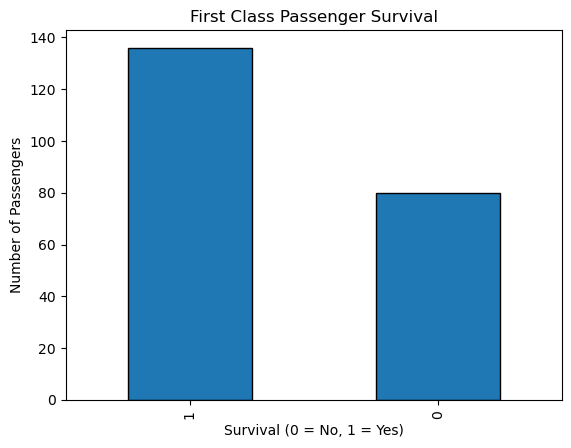

In [14]:
class1['Survived'].value_counts().plot(
    kind='bar',
    edgecolor='black'
)

plt.title("First Class Passenger Survival")
plt.xlabel("Survival (0 = No, 1 = Yes)")
plt.ylabel("Number of Passengers")

plt.show()

In [15]:
# Check duplicates
print("Duplicates:", df['PassengerId'].duplicated().sum())

# Remove duplicates
df.drop_duplicates(subset='PassengerId', keep='first', inplace=True)

# Verify
print("Duplicates after removal:",
      df['PassengerId'].duplicated().sum())

Duplicates: 0
Duplicates after removal: 0


In [16]:
df.insert(
    6,
    'FamilySize',
    df['SibSp'] + df['Parch'] + 1
)

print(df.head())
print(df)

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  \
0                            Braund, Mr. Owen Harris    male  22.0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0   
2                             Heikkinen, Miss. Laina  female  26.0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0   
4                           Allen, Mr. William Henry    male  35.0   

   FamilySize  SibSp  Parch            Ticket     Fare Cabin Embarked  
0           2      1      0         A/5 21171   7.2500   NaN        S  
1           2      1      0          PC 17599  71.2833   C85        C  
2           1      0      0  STON/O2. 3101282   7.9250   NaN        S  
3           2      1      0            113803  53.1000  C123        S  
4 